<a href="https://colab.research.google.com/github/juhisakshisurin/ITA0520-Computer-Vision/blob/main/Exp_28_Eye_Detection_Using_OpenCV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!pip install opencv-contrib-python-headless==4.14.0.94 --no-deps


Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 MB 46.1 MB/s  0:00:01


Saving eye_detection_input.jpg to eye_detection_input (2).jpg
Number of eyes detected: 3


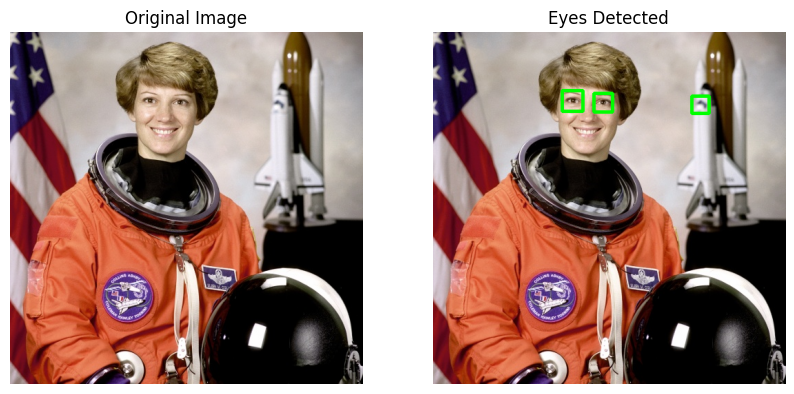

In [2]:

import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# Read image
image = cv2.imread(filename)

if image is None:
    raise ValueError("Unable to read the uploaded image.")

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Load eye detector
eye_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_eye.xml"
)

if eye_cascade.empty():
    raise RuntimeError("Eye detection model could not be loaded.")

# Detect eyes
eyes = eye_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5
)

# Copy image
result = image.copy()

# Draw rectangle around detected eyes
for (x, y, w, h) in eyes:
    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

print("Number of eyes detected:", len(eyes))

# Display original and detected images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Eyes Detected")
plt.axis("off")

plt.show()
